<a href="https://colab.research.google.com/github/FebryanAkt/Basic-PHP/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


2

In [10]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

3

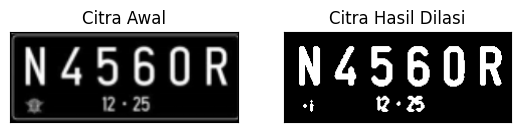

In [3]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    # Ukuran citra
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Inisialisasi Structuring Element Dilasi (SED) Cross 3x3
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi Manual
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# Load citra plat nomor dalam format grayscale
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

# Binerisasi citra
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

# Ukuran jendela / kernel w = 3 untuk cross 3x3
w = 3
imgD = dilasi_citra(thresh, w)

# Menampilkan hasil
plt.figure(figsize=(10, 5))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()


4

[[1 1 1]
 [1 1 1]
 [1 1 1]]


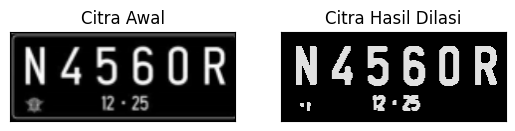

In [4]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

5

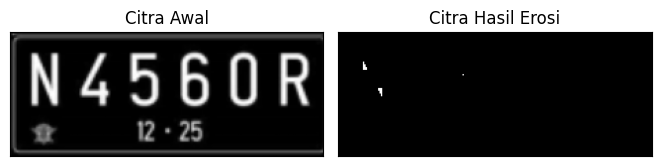

In [6]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 5. Fungsi Erosi Citra Tanpa Library OpenCV
def erosi_citra(F, k):
    m, n = F.shape

    # Generate structuring element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi Manual
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

path_img = '/content/drive/MyDrive/PCVK/plat nomer.png'
img_e = cv2.imread(path_img, 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

# Visualisasi Citra Awal dan Citra Hasil Erosi
plt.figure(figsize=(10, 5))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

6

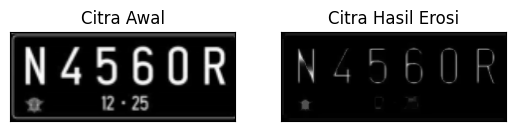

In [7]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png')
kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()


7

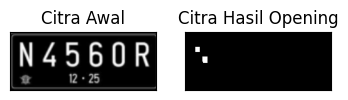

In [12]:
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structuring element bujur sangkar w x w
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_o = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

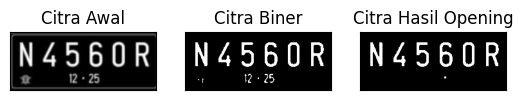

In [13]:
#Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

8

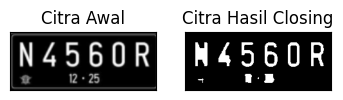

In [14]:
img_c = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

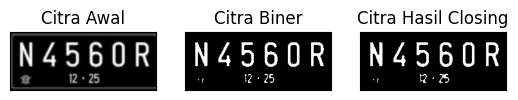

In [15]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

9

SED = Cross 3


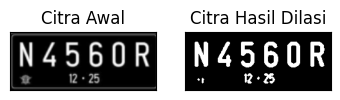

SED = Cross 5


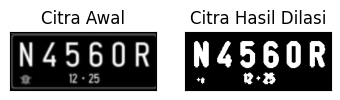

In [16]:
#Dilasi Cross SED
def dilasi_citra(F, w):
    #size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    #Generate structure element dilasi (SED)
    #SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

def dilasi_citra(F, w):
    #size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    #Generate structure element dilasi (SED)
    #SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

10

SED = Circle 3


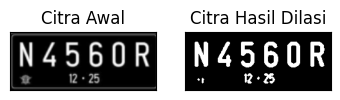

SED = Circle 5


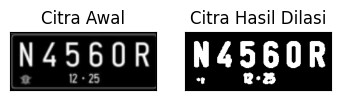

In [17]:
#Dilasi Circular SED
def dilasi_citra(F, w):
    #size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    #Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

11

SE = Rectangle 3x5


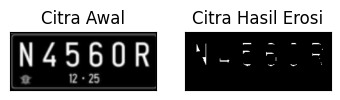

SE = Rectangle 5x7


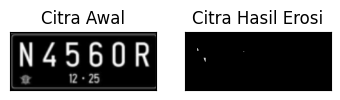

In [18]:
#Erosi Cross SE
def erosi_citra(F, p, l):
    #size image
    m, n = F.shape
    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l)) #SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)
    #Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

12

SE = Line Vertikal 3


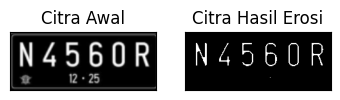

SE = Line Vertikal 5


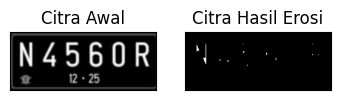

In [19]:
#Erosi Line Vertikal SE
def erosi_citra(F, k):
    #size image
    m, n = F.shape
    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k)) #SE line vertikal
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    #Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

13

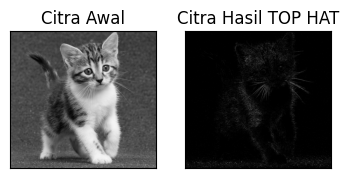

In [21]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

14

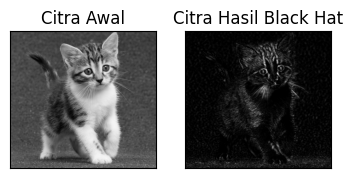

In [22]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

15

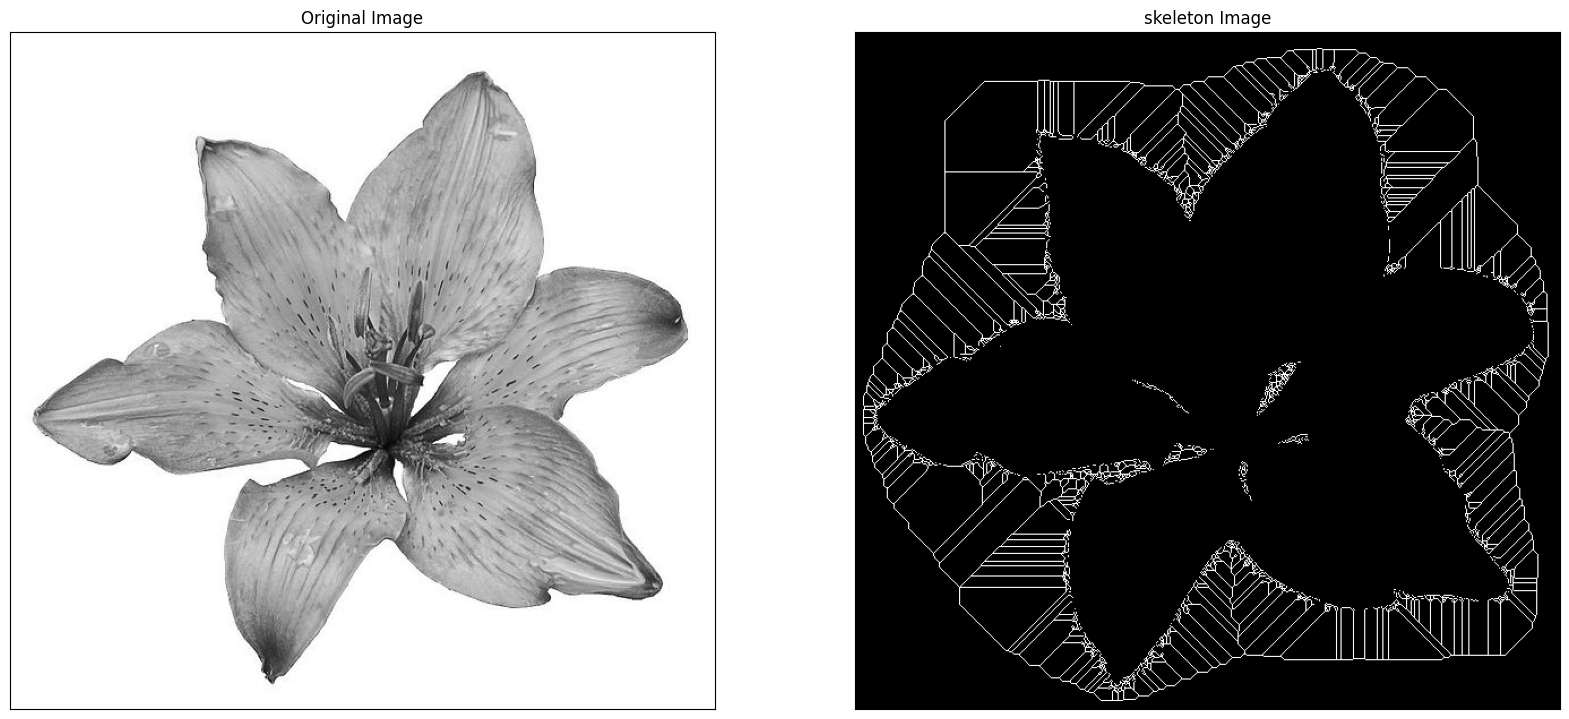

In [23]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/lily.jpg', 0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

16

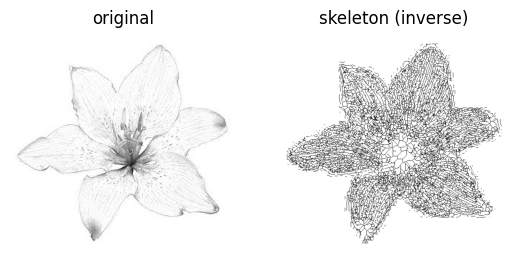

In [24]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

17

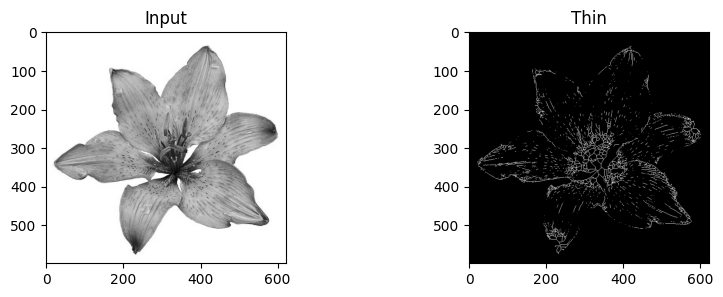

In [25]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/lily.jpg')))
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

# E. Tugas Praktikum


In [27]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


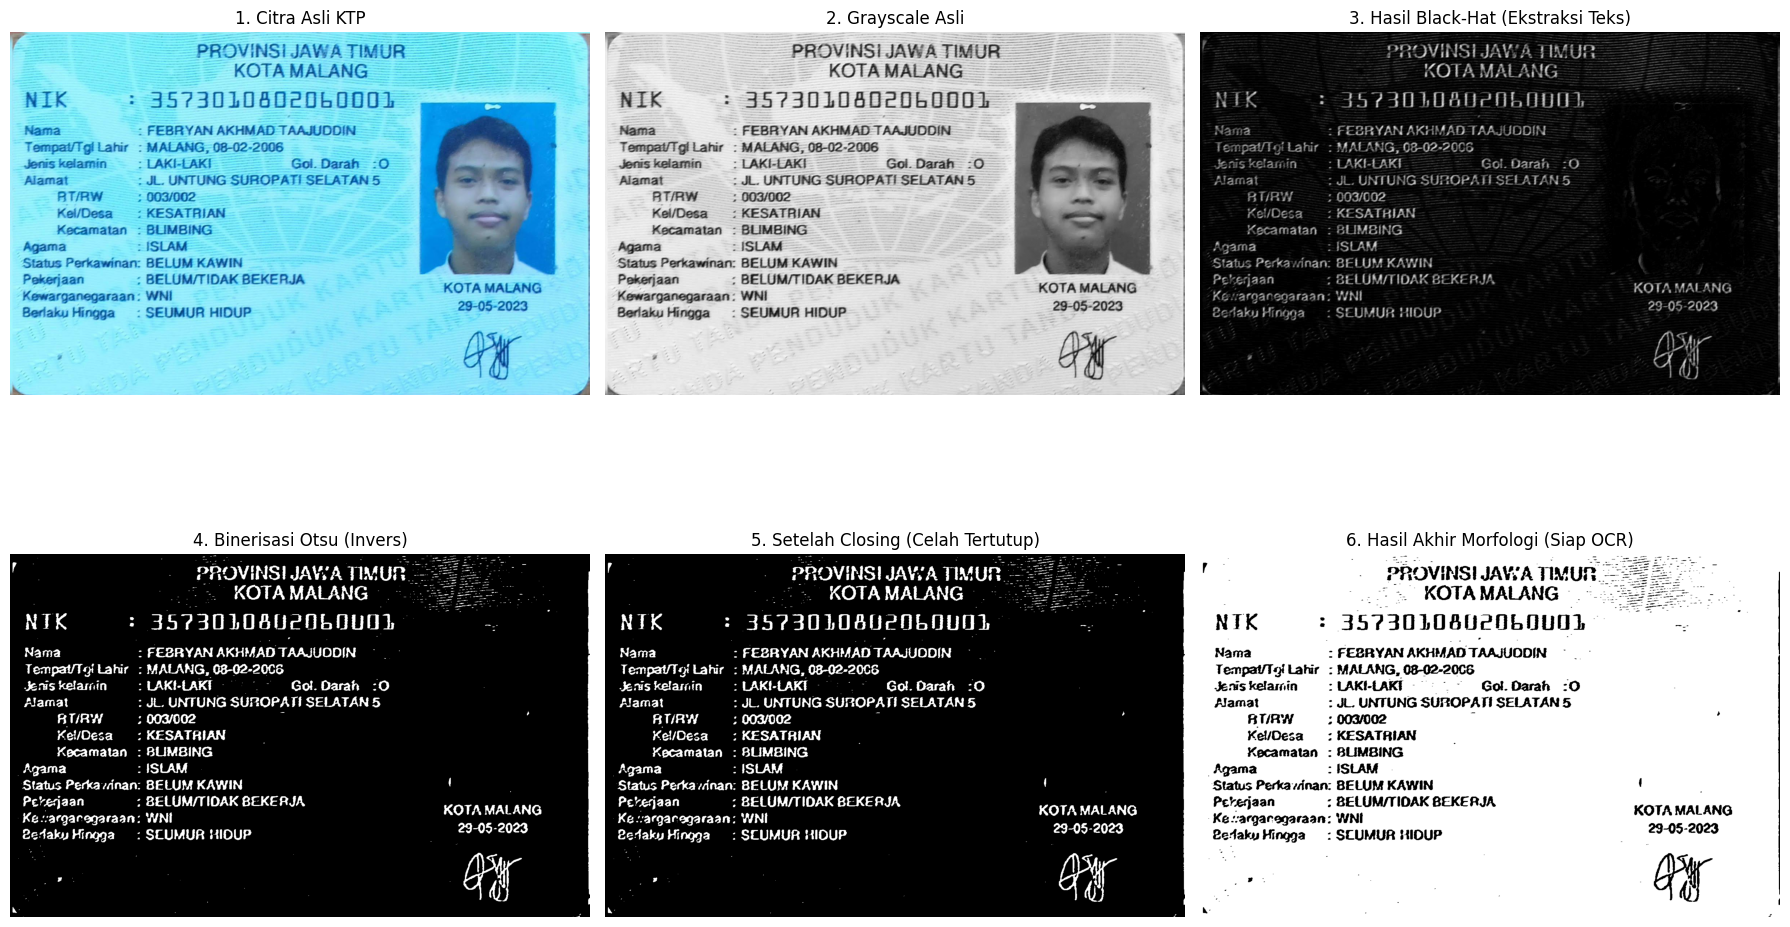

HASIL PEMBACAAN OCR SEBELUM OPERASI MORFOLOGI:
g PROVINSI JAWA TIMUR” |
KOTA MALANG ———————— |
NIK : 45?3010895256599501 — |
Nama - FEBRYAN AKHMAD TAAJUDDIN |
Tempat/Tgi Lahir : MALANG: 08-02-2006 . |
Jeris kelamin ——: LAKI-LAKI — GolDarah :O 2 au |
Alamat : JL. UNTUNG SUROPATI SELATAN 5
: |
RTJAW ——: 003/902
Kel/Desa — : KESATRIAN —— 4 ne | |
Kecamatan : BLIMBING |
Agama 1 ISLAM -
Status Perkawinan: BELUM KAWIN |
Pekerjaan : BELUM/TIDAK BEKERJA KOTA MALANG |
Kewarganegaraan: WNI |
Berlaku Hingga: SEUMUR HIDUP 29-05-2023
Tea 4

HASIL PEMBACAAN OCR SETELAH OPERASI MORFOLOGI:
ro | PROVINSIJAWA TIMUR
0235 KOTAMALANG 55
NTK : 35730108U2059U901———-—
Nama : FERRYAN AKHMAD TAAJUDDIN
Tempat/Tgi Lahir : MALANG, 08-02-2006
Jerus kelamin ILAKI-LAKI - Gol. Darah :0
Alamat : JL UNTUNG SUROPATI SELATAN 5
ATIAW — : 00002 '
KelDesa —: KESATAIAN
Kecamatan : BLUIMBING
Agama : ISLAM
Status Perkawinan: BELUM KAWIN (
Pekejaan : BELUM/TIDAK BEKERJA
Keargaronaraan: WNI KOTA MA ANG
Bedaku Hingga: SLUMUR HIDUP

In [28]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# Konfigurasi Tesseract OCR untuk Bahasa Indonesia
ocr_config = '--psm 6 -l ind'

# 1. Load Citra KTP
path_ktp = '/content/drive/MyDrive/PCVK/KTP_Febryan.jpeg'
img_bgr = cv.imread(path_ktp)

if img_bgr is None:
    raise FileNotFoundError(f"Citra pada path '{path_ktp}' tidak ditemukan. Pastikan path sudah benar.")

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

# 2. Prapemrosesan: Pengurangan Iluminasi Latar Belakang dengan Black-Hat
# Menggunakan kernel rectangular mendatar untuk menangkap struktur teks
kernel_blackhat = cv.getStructuringElement(cv.MORPH_RECT, (15, 5))
blackhat = cv.morphologyEx(img_gray, cv.MORPH_BLACKHAT, kernel_blackhat)

# Inversi: Teks menjadi gelap kembali di atas latar terang
inv_blackhat = cv.bitwise_not(blackhat)

# 3. Binerisasi Citra (Otsu Thresholding pada hasil Black-Hat)
blur = cv.GaussianBlur(inv_blackhat, (3, 3), 0)
_, thresh = cv.threshold(blur, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# 4. Operasi Morfologi untuk Perbaikan Kualitas Teks
# A. Closing: Menutup celah dan menyambung huruf yang putus-putus
kernel_close = cv.getStructuringElement(cv.MORPH_RECT, (2, 2))
img_closing = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel_close)

# B. Opening: Menghilangkan bintik-bintik noise halus di background
kernel_open = cv.getStructuringElement(cv.MORPH_RECT, (1, 1))
img_opening = cv.morphologyEx(img_closing, cv.MORPH_OPEN, kernel_open)

# C. Dilasi Tipis: Mempertegas ketebalan karakter agar mudah dibaca OCR
kernel_dilate = np.ones((1, 2), np.uint8)
img_morfologi = cv.dilate(img_opening, kernel_dilate, iterations=1)

# Inversi kembali untuk input standar Tesseract (Teks Hitam di atas Latar Putih)
hasil_akhir = cv.bitwise_not(img_morfologi)

# 5. Uji Pembacaan OCR (Tesseract)
teks_sebelum = pytesseract.image_to_string(img_gray, config=ocr_config)
teks_sesudah = pytesseract.image_to_string(hasil_akhir, config=ocr_config)

# 6. Visualisasi Perbandingan Tahapan Morfologi
plt.figure(figsize=(18, 12))

plt.subplot(2, 3, 1)
plt.imshow(img_rgb)
plt.title('1. Citra Asli KTP')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_gray, cmap='gray')
plt.title('2. Grayscale Asli')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(blackhat, cmap='gray')
plt.title('3. Hasil Black-Hat (Ekstraksi Teks)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(thresh, cmap='gray')
plt.title('4. Binerisasi Otsu (Invers)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_closing, cmap='gray')
plt.title('5. Setelah Closing (Celah Tertutup)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(hasil_akhir, cmap='gray')
plt.title('6. Hasil Akhir Morfologi (Siap OCR)')
plt.axis('off')

plt.tight_layout()
plt.show()

# 7. Tampilkan Hasil Teks
print("=" * 60)
print("HASIL PEMBACAAN OCR SEBELUM OPERASI MORFOLOGI:")
print("=" * 60)
print(teks_sebelum.strip())
print("\n" + "=" * 60)
print("HASIL PEMBACAAN OCR SETELAH OPERASI MORFOLOGI:")
print("=" * 60)
print(teks_sesudah.strip())
print("=" * 60)